# Simple Hypothesis-Testing Demo: EEG Cap vs MRI-Guided TMS Targeting

This notebook is designed as a short teaching example for someone new to statistical testing.

We pretend that each participant has the **same outcome measured with two localization methods**:

- MRI-guided neuronavigation
- EEG-cap localization

For the demo, the outcome is **mean induced electric field in the target ROI (V/m)**.

Because the two measurements come from the **same participants**, this is a **paired design**.

## 1. The basic research question

A simple first question is:

> Is there evidence of a systematic mean difference between the two methods?

For a paired t-test:

- **Null hypothesis, H₀:** mean(EEG − MRI) = 0
- **Alternative hypothesis, H₁:** mean(EEG − MRI) ≠ 0

We use a two-sided significance level of **α = 0.05**.

Important: failing to reject H₀ does **not** prove that the methods are equivalent.

In [1]:
# If needed:
# %pip install numpy pandas matplotlib statsmodels

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.stats.weightstats import DescrStatsW, ttost_paired

## 2. Example paired data

These are **simulated values for teaching only**. Replace them later with real subject-level measurements.

In [3]:
data = pd.DataFrame({
    "subject": np.arange(1, 13),
    "mri_efield": [82, 76, 91, 88, 79, 84, 95, 73, 86, 90, 81, 87],
    "eeg_efield": [80, 77, 89, 86, 80, 82, 93, 75, 84, 88, 82, 85],
})

# Paired difference: EEG minus MRI
data["difference"] = data["eeg_efield"] - data["mri_efield"]

data

,subject,mri_efield,eeg_efield,difference
0,1,82,80,-2
1,2,76,77,1
2,3,91,89,-2
3,4,88,86,-2
4,5,79,80,1
5,6,84,82,-2
6,7,95,93,-2
7,8,73,75,2
8,9,86,84,-2
9,10,90,88,-2


## 3. Look at the paired differences

The paired t-test is mathematically a **one-sample t-test on the within-subject differences**.

In [4]:
data["difference"].describe()

count    12.000000
mean     -0.916667
std       1.621354
min      -2.000000
25%      -2.000000
50%      -2.000000
75%       1.000000
max       2.000000
Name: difference, dtype: float64

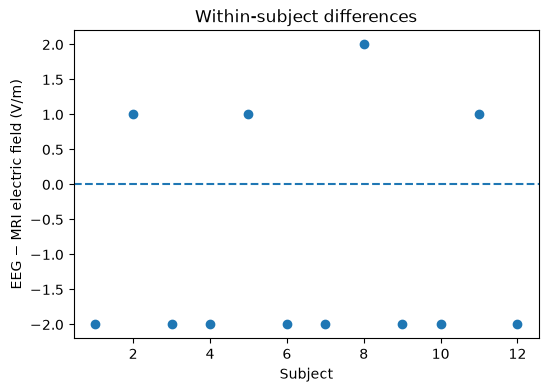

In [5]:
plt.figure(figsize=(6, 4))
plt.axhline(0, linestyle="--")
plt.scatter(data["subject"], data["difference"])
plt.xlabel("Subject")
plt.ylabel("EEG − MRI electric field (V/m)")
plt.title("Within-subject differences")
plt.show()

## 4. Run the paired t-test with `statsmodels`

`DescrStatsW(...).ttest_mean(0)` tests whether the mean paired difference is zero.

In [6]:
diff_stats = DescrStatsW(data["difference"])

t_stat, p_value, df = diff_stats.ttest_mean(
    value=0,
    alternative="two-sided"
)

ci_low, ci_high = diff_stats.tconfint_mean(alpha=0.05)

print(f"Mean difference (EEG - MRI): {data['difference'].mean():.2f} V/m")
print(f"95% CI: [{ci_low:.2f}, {ci_high:.2f}] V/m")
print(f"t({int(df)}) = {t_stat:.3f}")
print(f"p = {p_value:.4f}")

Mean difference (EEG - MRI): -0.92 V/m
95% CI: [-1.95, 0.11] V/m
t(11) = -1.959
p = 0.0760


## 5. Interpret the p-value

Use the preselected significance level **α = 0.05**:

- If **p < 0.05**, reject H₀: the data provide evidence of a non-zero mean difference.
- If **p ≥ 0.05**, do not reject H₀: the data do not provide enough evidence of a mean difference.

Do **not** interpret `p ≥ 0.05` as proof that the two methods are the same.

In [7]:
alpha = 0.05

if p_value < alpha:
    print("Reject H0: evidence of a systematic mean difference.")
else:
    print("Do not reject H0: insufficient evidence of a systematic mean difference.")

Do not reject H0: insufficient evidence of a systematic mean difference.


# Optional: connect this to the actual TMS positioning study

For this project, the stronger scientific question is not merely whether the methods differ, but whether the EEG method is **close enough to MRI-guided neuronavigation to satisfy a prespecified equivalence margin**.

That is an **equivalence test**, commonly implemented with **TOST (two one-sided tests)**.

Below is a simple demonstration. The ±5% margin is only an **illustrative teaching value**; the real study margin should be chosen *before* analysis using clinical/technical justification.

In [ ]:
# Percentage difference relative to MRI-guided measurement
data["pct_difference"] = 100 * (
    data["eeg_efield"] - data["mri_efield"]
) / data["mri_efield"]

data[["subject", "mri_efield", "eeg_efield", "pct_difference"]]

In [ ]:
# Illustrative equivalence bounds: -5% to +5%
lower_bound = -5
upper_bound = 5

zeros = np.zeros(len(data))

tost_p, lower_test, upper_test = ttost_paired(
    data["pct_difference"],
    zeros,
    low=lower_bound,
    upp=upper_bound
)

print(f"Mean percentage difference: {data['pct_difference'].mean():.2f}%")
print(f"Equivalence bounds: [{lower_bound}%, {upper_bound}%]")
print(f"TOST p-value: {tost_p:.4f}")

if tost_p < 0.05:
    print("Evidence supports equivalence within the prespecified bounds.")
else:
    print("Equivalence has not been demonstrated within the prespecified bounds.")

## Take-home message

This gives a useful teaching sequence:

1. Define H₀ and H₁.
2. Identify that the observations are paired.
3. Calculate each participant's difference.
4. Estimate the mean difference and confidence interval.
5. Run the paired t-test.
6. Interpret the p-value without treating non-significance as equivalence.
7. Introduce TOST when the scientific question is specifically **equivalence**.

For the real analysis, assumption checking, influential observations, repeated targets per participant, and multiple-testing correction would also need to be considered.